# Rossmann Store Sales Forecasting

## Step 1 — Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

# Change these paths if your CSV files are stored elsewhere
train = pd.read_csv("/Users/jaysutariya/ml_project/train.csv", parse_dates=["Date"])
store = pd.read_csv("/Users/jaysutariya/ml_project/store.csv")

print("Train shape:", train.shape)
print("Store shape:", store.shape)
display(train.head())
display(store.head())

Train shape: (1017209, 9)
Store shape: (1115, 10)


/var/folders/v0/sfxzgh4d4m5_h_gfsm8_vpp00000gn/T/ipykernel_10849/1122108193.py:18: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("/Users/jaysutariya/ml_project/train.csv", parse_dates=["Date"])


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## Step 2 — Understand and check the data
Check the columns, data types, missing values, duplicate records, and target summary. Do not delete columns just because they contain missing values; some missingness is meaningful.

In [2]:
print(train.info())
print(store.info())

train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), object(1)
memory usage: 69.8+ MB
None
<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,2014-04-11 01:30:42.846062,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
min,1.000000e+00,1.000000e+00,2013-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,2013-08-17 00:00:00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,2014-04-02 00:00:00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,2014-12-12 00:00:00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,2015-07-31 00:00:00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00
std,3.219087e+02,1.997391e+00,NaN,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01


In [3]:
store.describe()

,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00000,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000
mean,558.00000,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573
std,322.01708,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935
min,1.00000,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000
25%,279.50000,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000
50%,558.00000,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000
75%,836.50000,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000
max,1115.00000,75860.000000,12.000000,2015.000000,1.000000,50.000000,2015.000000


## Step 3 — Basic exploratory data analysis (EDA)
These charts help you understand sales patterns before training.

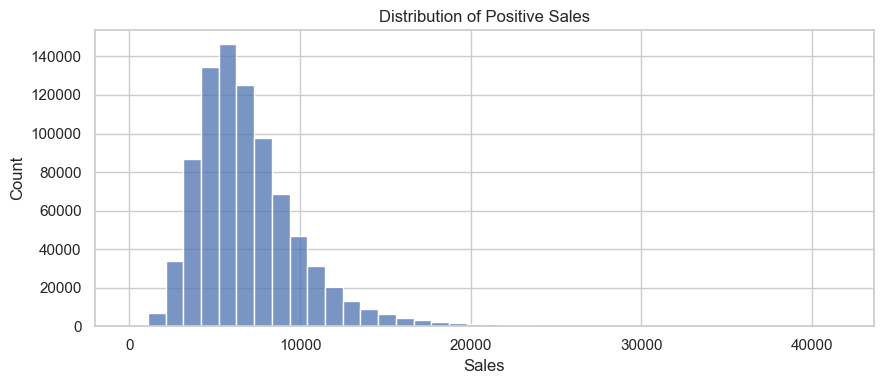

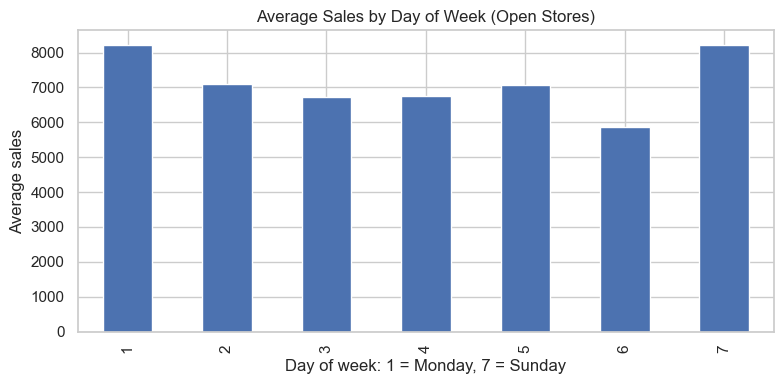

Average sales by promotion status:


,average_sales
Promo,
0,5929.407603
1,8228.281239


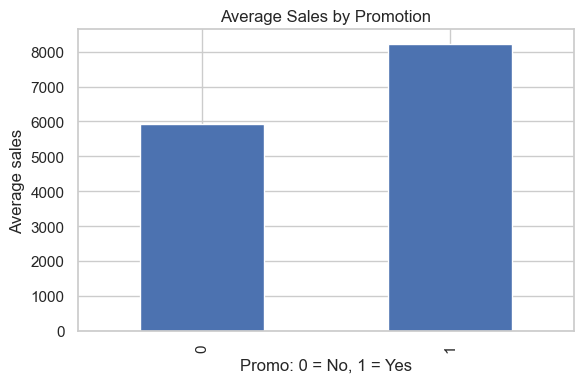

In [4]:
# Sales distribution, excluding zero-sales rows so the positive values are easier to inspect
plt.figure(figsize=(9, 4))
sns.histplot(data=train[train["Sales"] > 0], x="Sales", bins=40)
plt.title("Distribution of Positive Sales")
plt.tight_layout()
plt.show()

# Average sales by weekday for open stores
open_data = train[train["Open"] == 1].copy()
weekday_sales = open_data.groupby("DayOfWeek")["Sales"].mean()
weekday_sales.plot(kind="bar", figsize=(8, 4))
plt.title("Average Sales by Day of Week (Open Stores)")
plt.xlabel("Day of week: 1 = Monday, 7 = Sunday")
plt.ylabel("Average sales")
plt.tight_layout()
plt.show()

# Compare sales on promotion and non-promotion days
promo_sales = open_data.groupby("Promo")["Sales"].mean()
print("Average sales by promotion status:")
display(promo_sales.to_frame("average_sales"))
promo_sales.plot(kind="bar", figsize=(6, 4))
plt.title("Average Sales by Promotion")
plt.xlabel("Promo: 0 = No, 1 = Yes")
plt.ylabel("Average sales")
plt.tight_layout()
plt.show()

## Step 4 — Join store information and create simple features
We merge the two files using `Store`. We predict sales for open stores, so closed-store rows are excluded from model training. We create year/month/day/week features from the date. `Customers` and raw `Date` are not used as model inputs.

In [5]:
data = train.merge(store, on="Store", how="left", validate="many_to_one")
data = data[data["Open"] == 1].copy()

data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Day"] = data["Date"].dt.day
data["WeekOfYear"] = data["Date"].dt.isocalendar().week.astype(int)
data["IsWeekend"] = data["Date"].dt.dayofweek.isin([5, 6]).astype(int)

# Treat StateHoliday as a category; use a consistent string format
data["StateHoliday"] = data["StateHoliday"].astype(str).replace({"0.0": "0"})

print("Rows after merging and filtering open stores:", data.shape)
display(data.head())

Rows after merging and filtering open stores: (844392, 23)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear,IsWeekend
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,2008.0,0,NaN,NaN,NaN,2015,7,31,31,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,31,0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,31,0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,2009.0,0,NaN,NaN,NaN,2015,7,31,31,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,2015.0,0,NaN,NaN,NaN,2015,7,31,31,0


### More EDA — sales trends and seasonality
These charts use open stores only. Weekly averages make the overall trend easier to see, while the heatmap shows how month and weekday interact.

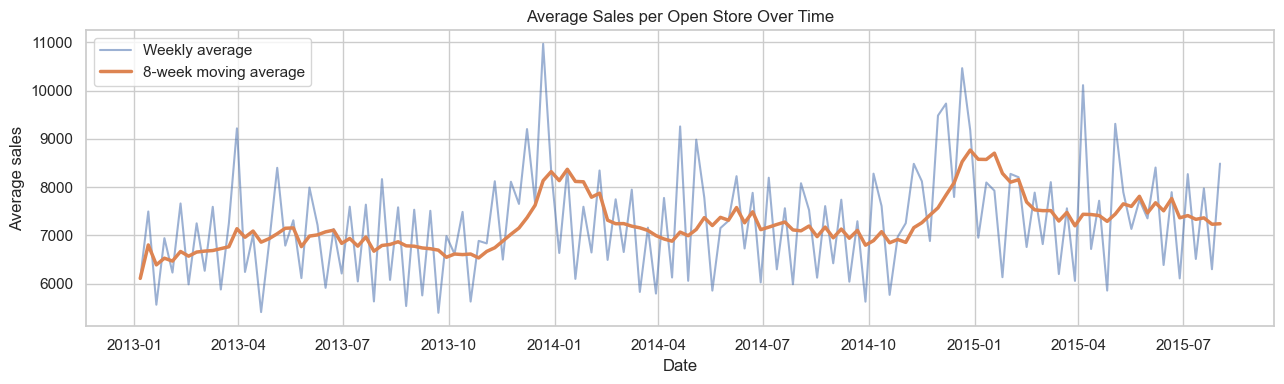

In [6]:
# Mean sales per open store on each date, summarized by week
daily_mean_sales = data.groupby("Date")["Sales"].mean().sort_index()
weekly_mean_sales = daily_mean_sales.resample("W").mean()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(weekly_mean_sales.index, weekly_mean_sales, alpha=0.55, label="Weekly average")
ax.plot(weekly_mean_sales.index, weekly_mean_sales.rolling(8, min_periods=1).mean(),
        linewidth=2.5, label="8-week moving average")
ax.set(title="Average Sales per Open Store Over Time", xlabel="Date", ylabel="Average sales")
ax.legend()
plt.tight_layout()
plt.show()

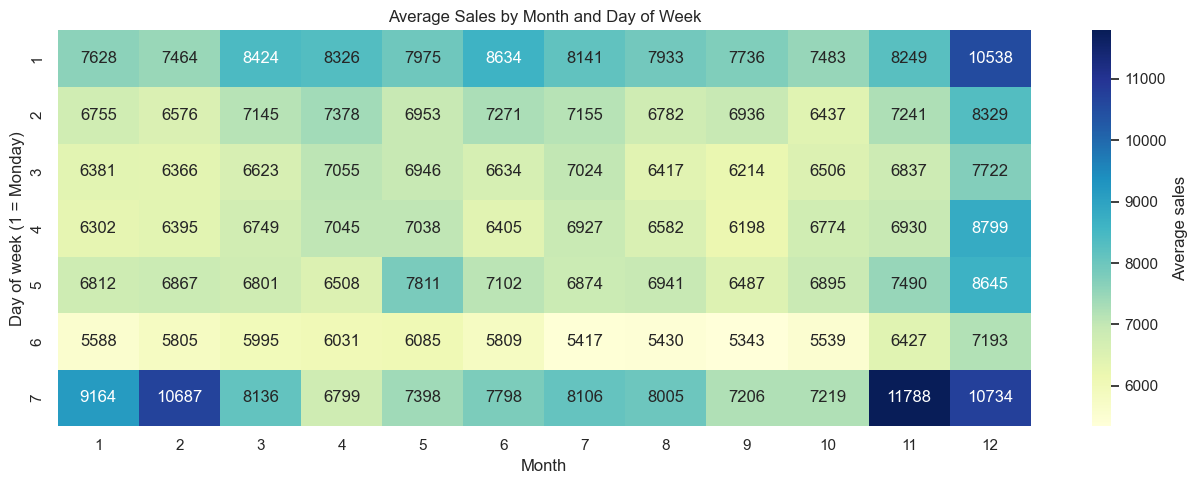

In [7]:
# Average sales by month and weekday across the available dates
month_weekday_sales = data.pivot_table(
    index="DayOfWeek", columns="Month", values="Sales", aggfunc="mean"
)
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(month_weekday_sales, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label": "Average sales"}, ax=ax)
ax.set(title="Average Sales by Month and Day of Week",
       xlabel="Month", ylabel="Day of week (1 = Monday)")
plt.tight_layout()
plt.show()

### More EDA — differences between store types
The bar chart compares promotion days within each store type. The box plot shows the spread of sales, using a fixed random sample to keep plotting responsive.

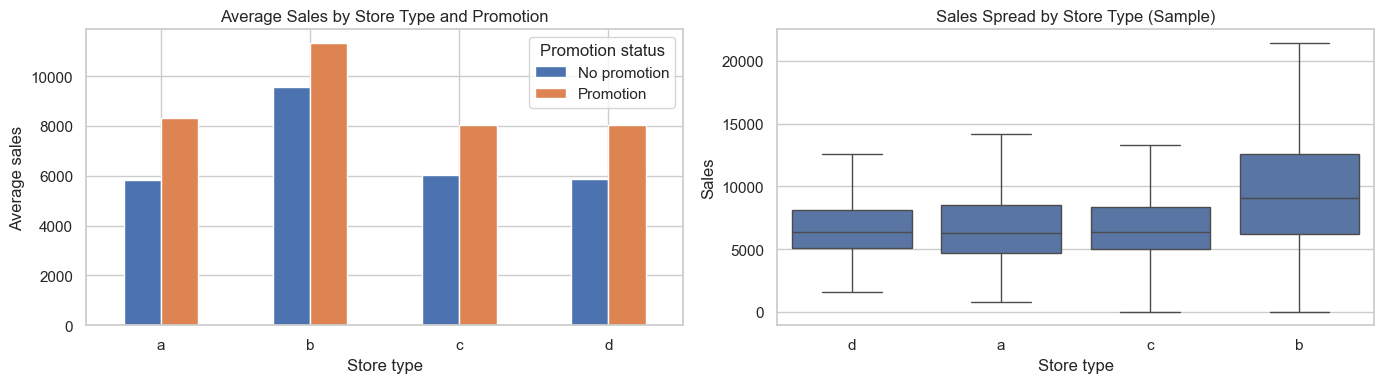

In [8]:
promo_by_store_type = data.groupby(["StoreType", "Promo"])["Sales"].mean().unstack()
promo_by_store_type = promo_by_store_type.rename(
    columns={0: "No promotion", 1: "Promotion"}
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
promo_by_store_type.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set(title="Average Sales by Store Type and Promotion",
            xlabel="Store type", ylabel="Average sales")
axes[0].legend(title="Promotion status")

store_sample = data.sample(n=min(20_000, len(data)), random_state=42)
sns.boxplot(data=store_sample, x="StoreType", y="Sales",
            showfliers=False, ax=axes[1])
axes[1].set(title="Sales Spread by Store Type (Sample)",
            xlabel="Store type", ylabel="Sales")
plt.tight_layout()
plt.show()

## Step 5 — Choose input features (X) and target (y)
`X` contains information available when making the forecast. `y` is the actual sales value. We deliberately exclude `Customers` to avoid using information that would not normally be known for a future date.

In [9]:
target = "Sales"

categorical_features = [
    "Store", "DayOfWeek", "StateHoliday", "StoreType", "Assortment", "PromoInterval"
]
numeric_features = [
    "Promo", "SchoolHoliday", "CompetitionDistance",
    "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
    "Promo2", "Promo2SinceWeek", "Promo2SinceYear",
    "Year", "Month", "Day", "WeekOfYear", "IsWeekend"
]

# Use only columns present in the merged data
categorical_features = [c for c in categorical_features if c in data.columns]
numeric_features = [c for c in numeric_features if c in data.columns]
feature_columns = categorical_features + numeric_features

X = data[feature_columns]
y = data[target]

print("Number of input features:", len(feature_columns))
print("Target:", target)
print("X shape:", X.shape, "| y shape:", y.shape)

Number of input features: 19
Target: Sales
X shape: (844392, 19) | y shape: (844392,)


## Step 6 — Split by time
For forecasting, train on earlier dates and validate on later dates. This better simulates predicting the future than randomly splitting rows.

In [10]:
validation_days = 42
cutoff_date = data["Date"].max() - pd.Timedelta(days=validation_days - 1)

train_data = data[data["Date"] < cutoff_date].copy()
valid_data = data[data["Date"] >= cutoff_date].copy()

X_train = train_data[feature_columns]
y_train = train_data[target]
X_valid = valid_data[feature_columns]
y_valid = valid_data[target]

print("Training dates:", train_data["Date"].min().date(), "to", train_data["Date"].max().date())
print("Validation dates:", valid_data["Date"].min().date(), "to", valid_data["Date"].max().date())
print("Training rows:", len(train_data))
print("Validation rows:", len(valid_data))

Training dates: 2013-01-01 to 2015-06-19
Validation dates: 2015-06-20 to 2015-07-31
Training rows: 804110
Validation rows: 40282


## Step 7 — Train a simple baseline model
The baseline predicts the median sales value from the training data. A more complex model should beat this benchmark.

In [11]:
baseline = DummyRegressor(strategy="median")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_valid), 1)))

baseline_mae = mean_absolute_error(y_valid, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_predictions))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 2204.31
Baseline RMSE: 3115.11


## Step 8 — Train Random Forest and XGBoost
Both models use the same preprocessing and the same training/validation split. XGBoost is trained with early stopping on the validation set.

In [13]:
# Shared preprocessing: impute missing values and encode categorical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_features),
    ("numeric", numeric_pipeline, numeric_features)
])

# Random Forest
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest...")
rf_model.fit(X_train, y_train)
rf_predictions = np.maximum(0, rf_model.predict(X_valid))
print("Random Forest training complete!")

# XGBoost: the same preprocessing converts object columns to numeric one-hot columns
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=700,
        learning_rate=0.05,
        max_depth=8,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=42
    ))
])

print("Training XGBoost...")
xgb_model.fit(X_train, y_train)
xgb_predictions = np.maximum(0, xgb_model.predict(X_valid))
print("XGBoost training complete!")

Training Random Forest...
Random Forest training complete!
Training XGBoost...
XGBoost training complete!


## Step 9 — Evaluate and compare models
Compare the median baseline, Random Forest, and XGBoost on the same validation dates. Lower MAE, RMSE, and RMSPE are better. RMSPE is calculated only for non-zero actual sales.

In [ ]:
def calculate_metrics(y_true, y_pred):
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    nonzero = actual != 0

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    rmspe = np.sqrt(np.mean(((actual[nonzero] - predicted[nonzero]) / actual[nonzero]) ** 2)) * 100

    return {"MAE": mae, "RMSE": rmse, "RMSPE (%)": rmspe}

baseline_metrics = calculate_metrics(y_valid, baseline_predictions)
rf_metrics = calculate_metrics(y_valid, rf_predictions)
xgb_metrics = calculate_metrics(y_valid, xgb_predictions)

results = pd.DataFrame([
    {"Model": "Median baseline", **baseline_metrics},
    {"Model": "Random Forest", **rf_metrics},
    {"Model": "XGBoost", **xgb_metrics}
])

results = results.sort_values("RMSPE (%)").reset_index(drop=True)
display(results.round(3))

# Select the best of Random Forest and XGBoost by RMSPE
model_predictions = {
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}
best_model_name = min(
    model_predictions,
    key=lambda name: calculate_metrics(y_valid, model_predictions[name])["RMSPE (%)"]
)
best_predictions = model_predictions[best_model_name]

print("Best model based on validation RMSPE:", best_model_name)
print("Its metrics:", calculate_metrics(y_valid, best_predictions))

,Model,MAE,RMSE,RMSPE (%)
0,XGBoost,1147.503,1487.476,28.323
1,Random Forest,1539.585,2044.817,38.541
2,Median baseline,2204.307,3115.111,51.291


Best model based on validation RMSPE: XGBoost
Its metrics: {'MAE': 1147.5031791555568, 'RMSE': np.float64(1487.4758496505979), 'RMSPE (%)': np.float64(28.323031455957054)}


## Step 10 — Compare actual and predicted sales
The chart below uses the model with the lower validation RMSPE.

,Store,Date,Actual_Sales,Predicted_Sales,Absolute_Error
0,1,2015-07-31,5263,7626.246582,2363.246582
1,2,2015-07-31,6064,7541.670898,1477.670898
2,3,2015-07-31,8314,7917.139648,396.860352
3,4,2015-07-31,13995,10460.023438,3534.976562
4,5,2015-07-31,4822,7217.991699,2395.991699
5,6,2015-07-31,5651,8539.460938,2888.460938
6,7,2015-07-31,15344,9856.643555,5487.356445
7,8,2015-07-31,8492,8446.552734,45.447266
8,9,2015-07-31,8565,9257.329102,692.329102
9,10,2015-07-31,7185,8226.106445,1041.106445


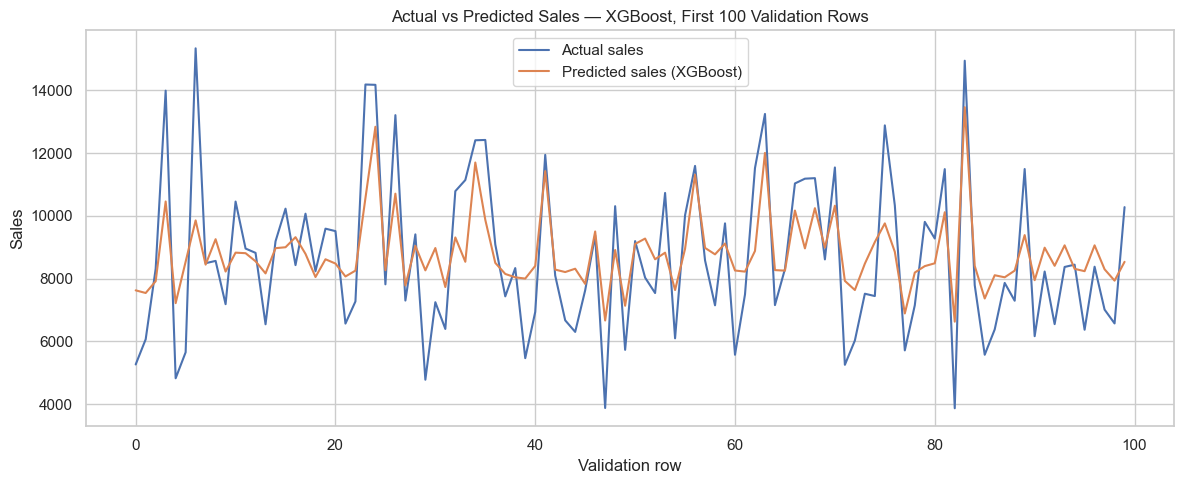

Saved model_comparison_results.csv and validation_predictions.csv


In [ ]:
comparison = valid_data[["Store", "Date", "Sales"]].copy()
comparison = comparison.rename(columns={"Sales": "Actual_Sales"})
comparison["Predicted_Sales"] = best_predictions
comparison["Absolute_Error"] = abs(
    comparison["Actual_Sales"] - comparison["Predicted_Sales"]
)

display(comparison.head(10))

sample = comparison.head(100).reset_index(drop=True)
plt.figure(figsize=(12, 5))
plt.plot(sample["Actual_Sales"], label="Actual sales")
plt.plot(sample["Predicted_Sales"], label=f"Predicted sales ({best_model_name})")
plt.title(f"Actual vs Predicted Sales — {best_model_name}, First 100 Validation Rows")
plt.xlabel("Validation row")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

# Save model comparison and validation predictions
results.to_csv("model_comparison_results.csv", index=False)
comparison.to_csv("validation_predictions.csv", index=False)
print("Saved model_comparison_results.csv and validation_predictions.csv")

### More validation charts — trends and errors
These charts show whether the selected model follows the validation-period trend and where its predictions differ from actual sales.

In [ ]:
# Daily averages are easier to compare than the first 100 unsorted rows
validation_daily = comparison.groupby("Date")[["Actual_Sales", "Predicted_Sales"]].mean()
fig, ax = plt.subplots(figsize=(13, 4))
validation_daily.plot(ax=ax, linewidth=2)
ax.set(title=f"Daily Average Sales: Actual vs {best_model_name}",
       xlabel="Validation date", ylabel="Average sales per open store")
ax.legend(["Actual sales", "Predicted sales"])
plt.tight_layout()
plt.show()

In [ ]:
# Signed errors reveal overprediction and underprediction
signed_error = comparison["Predicted_Sales"] - comparison["Actual_Sales"]
plot_sample = comparison.sample(n=min(10_000, len(comparison)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(signed_error, bins=50, ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(title=f"Prediction Errors — {best_model_name}",
            xlabel="Predicted minus actual sales", ylabel="Validation rows")

axes[1].scatter(plot_sample["Actual_Sales"], plot_sample["Predicted_Sales"],
                s=8, alpha=0.2)
plot_limit = max(plot_sample["Actual_Sales"].max(),
                 plot_sample["Predicted_Sales"].max())
axes[1].plot([0, plot_limit], [0, plot_limit], "k--", linewidth=1)
axes[1].set(title="Actual vs Predicted Sales (Sample)",
            xlabel="Actual sales", ylabel="Predicted sales",
            xlim=(0, plot_limit), ylim=(0, plot_limit))
plt.tight_layout()
plt.show()

## Step 11 — Predict sales for a sample row
This demonstrates how the trained model produces a numerical sales prediction for a validation record. It is not a prediction for a brand-new manually entered date.

In [ ]:
sample_input = X_valid.iloc[[0]]
sample_prediction = best_predictions[0]
actual_value = y_valid.iloc[0]

print("Selected model:", best_model_name)
print("Store:", valid_data.iloc[0]["Store"])
print("Date:", valid_data.iloc[0]["Date"].date())
print("Actual sales:", actual_value)
print("Predicted sales:", round(float(sample_prediction), 2))

Selected model: XGBoost
Store: 1
Date: 2015-07-31
Actual sales: 5263
Predicted sales: 7626.25


## Step 12 — Improve performance with LightGBM and Hyperparameter Tuning

First, we'll import LightGBM and set up a Pipeline for it. LightGBM is highly efficient and optimized for speed and accuracy.

In [ ]:
import lightgbm as lgb

lgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=63,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training LightGBM model...")
lgb_model.fit(X_train, y_train)
lgb_predictions = np.maximum(0, lgb_model.predict(X_valid))

lgb_metrics = calculate_metrics(y_valid, lgb_predictions)
print("LightGBM Validation Metrics:", lgb_metrics)

Training LightGBM model...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014822 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2706
[LightGBM] [Info] Number of data points in the train set: 804110, number of used features: 1149
[LightGBM] [Info] Start training from score 6954.355903
LightGBM Validation Metrics: {'MAE': 782.9614850028348, 'RMSE': np.float64(1100.4328728661194), 'RMSPE (%)': np.float64(18.2815884935475)}


Next, let's implement a randomized hyperparameter search for **XGBoost** to fine-tune its performance over key parameters like `max_depth`, `learning_rate`, and `subsample`.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# We will tune the XGBoost regressor directly using preprocessed features to speed up search
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_valid_preprocessed = preprocessor.transform(X_valid)

param_dist = {
    'n_estimators': [500, 700, 1000],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [6, 8, 10],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

xgb_tune = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

# Perform 5-fold randomized search
random_search = RandomizedSearchCV(
    estimator=xgb_tune,
    param_distributions=param_dist,
    n_iter=5,
    scoring='neg_mean_absolute_error',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Starting Hyperparameter Tuning on XGBoost...")
random_search.fit(X_train_preprocessed, y_train)

best_xgb = random_search.best_estimator_
tuned_xgb_predictions = np.maximum(0, best_xgb.predict(X_valid_preprocessed))

tuned_xgb_metrics = calculate_metrics(y_valid, tuned_xgb_predictions)
print("Best parameters found:", random_search.best_params_)
print("Tuned XGBoost Validation Metrics:", tuned_xgb_metrics)

Starting Hyperparameter Tuning on XGBoost...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best parameters found: {'subsample': 0.8, 'n_estimators': 1000, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_bytree': 0.9}
Tuned XGBoost Validation Metrics: {'MAE': 867.0331562751159, 'RMSE': np.float64(1183.890961369817), 'RMSPE (%)': np.float64(21.122305386589765)}


In [ ]:
# Let's update and display the model comparison table
updated_results = pd.DataFrame([
    {"Model": "Median baseline", **baseline_metrics},
    {"Model": "Random Forest", **rf_metrics},
    {"Model": "XGBoost (Default)", **xgb_metrics},
    {"Model": "LightGBM", **lgb_metrics},
    {"Model": "Tuned XGBoost", **tuned_xgb_metrics}
])

updated_results = updated_results.sort_values("RMSPE (%)").reset_index(drop=True)
display(updated_results.round(3))

,Model,MAE,RMSE,RMSPE (%)
0,LightGBM,782.961,1100.433,18.282
1,Tuned XGBoost,867.033,1183.891,21.122
2,XGBoost (Default),1147.503,1487.476,28.323
3,Random Forest,1539.585,2044.817,38.541
4,Median baseline,2204.307,3115.111,51.291


### Visual comparison of all models
Each metric has its own scale. Shorter bars indicate better validation performance.

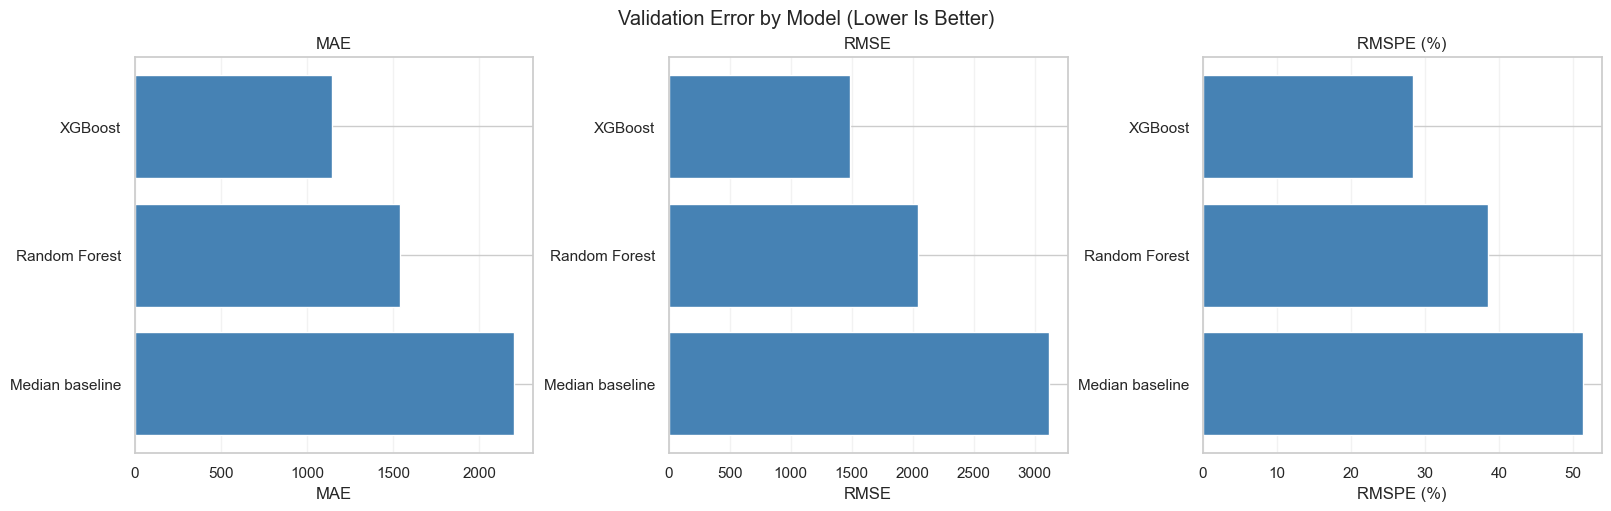

In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Prefer the full comparison; use earlier or saved results after a kernel restart.
if "updated_results" in globals():
    plot_results = updated_results.copy()
elif "results" in globals():
    plot_results = results.copy()
elif Path("model_comparison_results.csv").exists():
    plot_results = pd.read_csv("model_comparison_results.csv")
else:
    raise RuntimeError("Run the model evaluation cells before plotting.")

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, metric in zip(axes, ["MAE", "RMSE", "RMSPE (%)"]):
    ax.barh(plot_results["Model"], plot_results[metric], color="steelblue")
    ax.invert_yaxis()
    ax.set(title=metric, xlabel=metric)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle("Validation Error by Model (Lower Is Better)")
plt.show()

## Final conclusion
After running all cells, use the printed comparison table to see whether Random Forest or XGBoost performs better on the same time-based validation period. The notebook selects the model with the lower validation RMSPE and saves the metrics and validation predictions.

Do not assume which model wins before running the notebook. The result depends on the data and validation period.

This notebook is intended for learning and academic evaluation. It does not include deployment, APIs, Docker, or monitoring.